In [0]:
spark.sql("SHOW CATALOGS").show(truncate=False)

+---------+
|catalog  |
+---------+
|samples  |
|system   |
|workspace|
+---------+



In [0]:
spark.sql("SHOW SCHEMAS IN workspace").show(truncate=False)

+------------------+
|databaseName      |
+------------------+
|default           |
|information_schema|
+------------------+



In [0]:
%sql
CREATE VOLUME IF NOT EXISTS workspace.default.themepark_assessment;

In [0]:
BASE_PATH = "/Volumes/workspace/default/themepark_assessment"
display(dbutils.fs.ls(BASE_PATH))

path,name,size,modificationTime
dbfs:/Volumes/workspace/default/themepark_assessment/attraction_maintenance.csv,attraction_maintenance.csv,1324,1794373584000
dbfs:/Volumes/workspace/default/themepark_assessment/attractions.json,attractions.json,2562,1794373584000
dbfs:/Volumes/workspace/default/themepark_assessment/park_entries.csv,park_entries.csv,8592,1794373584000
dbfs:/Volumes/workspace/default/themepark_assessment/park_entries_incremental.csv,park_entries_incremental.csv,911,1794373584000
dbfs:/Volumes/workspace/default/themepark_assessment/park_entry_changes.csv,park_entry_changes.csv,823,1794373584000


In [0]:
from pyspark.sql.types import (StructType, StructField, StringType, IntegerType, DoubleType)
CATALOG = "workspace"      
SCHEMA = "default"   
BASE_PATH = "/Volumes/workspace/default/themepark_assessment"  
prefix = f"{CATALOG}.{SCHEMA}"
entry_schema = StructType([
    StructField("entry_id", IntegerType(), True),
    StructField("visitor_id", StringType(), True),
    StructField("attraction_id", StringType(), True),
    StructField("visit_date", StringType(), True),
    StructField("entry_time", StringType(), True),
    StructField("wait_minutes", IntegerType(), True),
    StructField("ride_minutes", IntegerType(), True),
    StructField("ticket_type", StringType(), True),
    StructField("ticket_price", DoubleType(), True),
    StructField("status", StringType(), True),
    StructField("booking_channel", StringType(), True)
])
maintenance_schema = StructType([
    StructField("maintenance_id", StringType(), True),
    StructField("attraction_id", StringType(), True),
    StructField("maintenance_date", StringType(), True),
    StructField("issue_type", StringType(), True),
    StructField("downtime_minutes", IntegerType(), True),
    StructField("maintenance_status", StringType(), True)
])

In [0]:
def read_csv(filename, schema):
    return (spark.read.format("csv")
            .option("header", "true")
            .schema(schema)
            .load(f"{BASE_PATH}/{filename}"))
entries = read_csv("park_entries.csv", entry_schema)
attractions = spark.read.json(f"{BASE_PATH}/attractions.json")
maintenance = read_csv("attraction_maintenance.csv", maintenance_schema)
changes = read_csv("park_entry_changes.csv", entry_schema)

In [0]:
entries.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"{prefix}.tp_entries_raw")
attractions.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"{prefix}.tp_attractions")
maintenance.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"{prefix}.tp_maintenance")
changes.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"{prefix}.tp_entry_changes")


In [0]:
for name in ["tp_entries_raw", "tp_attractions", "tp_maintenance", "tp_entry_changes"]:
    print(f"{prefix}.{name}: {spark.table(f'{prefix}.{name}').count()} rows")
display(spark.table(f"{prefix}.tp_entries_raw").limit(10))


workspace.default.tp_entries_raw: 121 rows
workspace.default.tp_attractions: 10 rows
workspace.default.tp_maintenance: 28 rows
workspace.default.tp_entry_changes: 10 rows


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk


In [0]:
catalog = "workspace"       
schema = "default"
prefix = f"{catalog}.{schema}"
df = spark.table(f"{prefix}.tp_entries_raw")
attractions_df = spark.table(f"{prefix}.tp_attractions")
maintenance_df = spark.table(f"{prefix}.tp_maintenance")
changes_df = spark.table(f"{prefix}.tp_entry_changes")
df.createOrReplaceTempView("entries")
attractions_df.createOrReplaceTempView("attractions")
maintenance_df.createOrReplaceTempView("maintenance")
changes_df.createOrReplaceTempView("entry_changes")


## A. Data ingestion and exploration

01. Load the supplied CSV and JSON datasets using the setup notebook. Display each table and verify its
row count.

In [0]:
tables = [
    "tp_entries_raw",
    "tp_attractions",
    "tp_maintenance",
    "tp_entry_changes"
]
for table in tables:
    df1=spark.table(f"workspace.default.{table}")
    print(table, df1.count())
    display(df1)

tp_entries_raw 121


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk


tp_attractions 10


attraction_id,attraction_name,capacity_per_hour,category,features,is_active,location,min_height_cm,opened_year
A01,Sky Spinner,140,Thrill,"List(Outdoor, High Speed)",true,"List(N1, North)",120,2018
A02,Coral Carousel,200,Family,"List(Indoor, Family Friendly)",true,"List(E2, East)",0,2015
A03,Jungle Rapids,110,Water,"List(Water Ride, Outdoor)",true,"List(S1, South)",110,2020
A04,Moonlight Train,180,Family,"List(Scenic, Family Friendly)",true,"List(W3, West)",0,2012
A05,Meteor Drop,100,Thrill,"List(High Speed, Outdoor)",true,"List(N2, North)",135,2022
A06,Pirate Voyage,130,Water,"List(Water Ride, Themed)",true,"List(E1, East)",100,2019
A07,Crystal Maze,160,Adventure,"List(Indoor, Puzzle)",true,"List(S3, South)",90,2021
A08,Forest Flyers,120,Adventure,"List(Outdoor, Interactive)",true,"List(W1, West)",115,2023
A09,Galaxy Theater,260,Show,"List(Indoor, Live Show)",true,"List(N3, North)",0,2017
A10,Mini Explorers,190,Family,"List(Kids, Indoor)",true,"List(E3, East)",0,2016


tp_maintenance 28


maintenance_id,attraction_id,maintenance_date,issue_type,downtime_minutes,maintenance_status
M001,A05,2026-10-15,Cleaning,90,Scheduled
M002,A08,2026-10-05,Mechanical,60,Completed
M003,A02,2026-10-12,Mechanical,0,Scheduled
M004,A09,2026-10-18,Electrical,0,Open
M005,A05,2026-10-12,Electrical,0,Scheduled
M006,A04,2026-10-07,Water System,45,Completed
M007,A10,2026-10-20,Mechanical,120,Completed
M008,A04,2026-10-04,Water System,90,Open
M009,A08,2026-10-19,Safety Check,30,Scheduled
M010,A02,2026-10-15,Safety Check,0,Open


tp_entry_changes 10


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,675.0,Completed,App
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,500.0,Completed,App
1068,V531,A10,2026-10-15,16:20:00,30,4,Express,725.0,Completed,App
1095,V563,A07,2026-10-09,11:20:00,75,4,Standard,500.0,Completed,App
1121,V700,A01,2026-10-20,11:00:00,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,12:00:00,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,13:00:00,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,14:00:00,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,15:00:00,35,16,Standard,350.0,Completed,Web


02. Inspect the schema of tp_entries_raw. Identify string, integer, and decimal columns.

In [0]:
df.printSchema()

root
 |-- entry_id: integer (nullable = true)
 |-- visitor_id: string (nullable = true)
 |-- attraction_id: string (nullable = true)
 |-- visit_date: string (nullable = true)
 |-- entry_time: string (nullable = true)
 |-- wait_minutes: integer (nullable = true)
 |-- ride_minutes: integer (nullable = true)
 |-- ticket_type: string (nullable = true)
 |-- ticket_price: double (nullable = true)
 |-- status: string (nullable = true)
 |-- booking_channel: string (nullable = true)



03. Select entry_id, attraction_id, visit_date, ticket_type, and ticket_price. Display the first 20 rows.

In [0]:
df.select(
    "entry_id",
    "attraction_id",
    "visit_date",
    "ticket_type",
    "ticket_price"
).show(20)

+--------+-------------+----------+-----------+------------+
|entry_id|attraction_id|visit_date|ticket_type|ticket_price|
+--------+-------------+----------+-----------+------------+
|    1001|          A08|2026-10-06|   Standard|       350.0|
|    1002|          A01|2026-10-10|   Standard|       350.0|
|    1003|          A04|2026-10-11|   Standard|       350.0|
|    1004|          A05|2026-10-15|    Express|       650.0|
|    1005|          A07|2026-10-07|   Standard|       350.0|
|    1006|          A08|2026-10-09|        VIP|       900.0|
|    1007|          A08|2026-10-14|   Standard|       350.0|
|    1008|          A06|2026-10-01|    Express|       650.0|
|    1009|          A02|2026-10-16|   Standard|       350.0|
|    1010|          A02|2026-10-09|    Express|       600.0|
|    1011|          A02|2026-10-06|   Standard|       350.0|
|    1012|          A07|2026-10-13|    Express|       600.0|
|    1013|          A09|2026-10-11|   Standard|       350.0|
|    1014|          A07|

04. Using SQL, find Completed entries where ticket_price is greater than 500.

In [0]:
%sql
SELECT * FROM entries WHERE status = 'Completed' AND ticket_price > 500

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1014,V564,A07,2026-10-01,14:10:00,65,4,VIP,900.0,Completed,Partner
1018,V535,A10,2026-10-01,13:10:00,65,8,Express,600.0,Completed,App
1021,V527,A03,2026-10-02,13:00:00,-8,8,Express,650.0,Completed,Web
1022,V543,A09,2026-10-15,17:20:00,65,4,Express,600.0,Completed,App
1024,V537,A06,2026-10-06,17:30:00,50,8,Express,650.0,Completed,Web
1025,V513,A09,2026-10-08,14:20:00,65,12,Express,600.0,Completed,App
1028,V547,A08,2026-10-02,13:20:00,75,12,Express,600.0,Completed,App


05. Use DISTINCT and IN to examine ticket types and booking channels.

In [0]:
%sql
SELECT DISTINCT ticket_type FROM entries;

ticket_type
Standard
Express
VIP


In [0]:
%sql
SELECT * FROM entries WHERE ticket_type IN ('Standard', 'Express');

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk
1011,V536,A02,2026-10-06,16:40:00,25,8,Standard,350.0,Cancelled,App


In [0]:
%sql
SELECT DISTINCT booking_channel FROM entries;

booking_channel
App
Web
Kiosk
Partner
null


In [0]:
%sql
SELECT * FROM  entries WHERE booking_channel IN ('App', 'Web');

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1011,V536,A02,2026-10-06,16:40:00,25,8,Standard,350.0,Cancelled,App
1012,V543,A07,2026-10-13,12:20:00,25,20,Express,600.0,Cancelled,Web
1013,V506,A09,2026-10-11,10:20:00,15,20,Standard,350.0,Completed,Web
1018,V535,A10,2026-10-01,13:10:00,65,8,Express,600.0,Completed,App


06. Convert visit_date to a date type and count entries by visit date.

In [0]:
from pyspark.sql.functions import to_date, count
date_df = df.withColumn(
    "visit_date",
    to_date("visit_date")
)
date_df.groupBy("visit_date").agg(
    count("*").alias("total_entries")
).orderBy("visit_date").show()

+----------+-------------+
|visit_date|total_entries|
+----------+-------------+
|2026-10-01|           11|
|2026-10-02|            4|
|2026-10-03|           13|
|2026-10-04|            7|
|2026-10-05|            4|
|2026-10-06|            6|
|2026-10-07|            8|
|2026-10-08|            7|
|2026-10-09|           10|
|2026-10-10|            7|
|2026-10-11|            9|
|2026-10-12|            6|
|2026-10-13|            6|
|2026-10-14|            7|
|2026-10-15|            8|
|2026-10-16|            8|
+----------+-------------+



##B. Cleaning and transforming with PySpark

07. Find records with missing ticket_price or booking_channel values.

In [0]:
from pyspark.sql.functions import col
missing_df = spark.table("workspace.default.tp_entries_raw").filter(
    col("ticket_price").isNull() |
    col("booking_channel").isNull()
)
display(missing_df)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1016,V563,A10,2026-10-08,15:10:00,30,10,Standard,null,Completed,Kiosk
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,400.0,Completed,null
1071,V553,A07,2026-10-03,11:10:00,5,20,Standard,null,Completed,Partner
1087,V537,A01,2026-10-11,10:00:00,75,4,Standard,350.0,Completed,null


08. Fill missing booking_channel values with Unknown in a new DataFrame; do not change the raw source.

In [0]:
clean_df = df.fillna({"booking_channel": "Unknown"})
display(clean_df)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,Unknown
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk


09. Identify records with negative wait_minutes, zero ride_minutes, or nonpositive ticket_price.

In [0]:
display(df.filter(
    (col("wait_minutes") < 0) |
    (col("ride_minutes") == 0) |
    (col("ticket_price") <= 0)
))

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1021,V527,A03,2026-10-02,13:00:00,-8,8,Express,650.0,Completed,Web
1036,V527,A06,2026-10-04,14:40:00,40,0,Standard,400.0,Completed,Kiosk
1058,V516,A02,2026-10-08,19:10:00,30,4,Standard,0.0,Completed,App
1073,V501,A03,2026-10-07,18:50:00,-3,6,Express,650.0,Completed,App


10. Find duplicate entry_id values and create a deduplicated DataFrame.

In [0]:
display(df.groupBy("entry_id").count().filter(col("count") > 1))
deduplicated_df = df.dropDuplicates(["entry_id"])

entry_id,count
1032,2


11. Identify entry records whose attraction_id is missing from the attraction master.

In [0]:
display(
    df.join(
        attractions_df,
        on="attraction_id",
        how="left_anti"
    )
)

attraction_id,entry_id,visitor_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
A99,1092,V566,2026-10-03,15:40:00,75,20,Standard,400.0,Completed,Kiosk


12. Create wait_category: Short (0-20), Medium (21-45), Long (above 45). Exclude invalid waits.

In [0]:
from pyspark.sql.functions import when
wait_df = df.filter(col("wait_minutes") >= 0)
wait_df = wait_df.withColumn(
    "wait_category",
    when(col("wait_minutes") <= 20, "Short")
    .when(col("wait_minutes") <= 45, "Medium")
    .otherwise("Long")
)
display(wait_df)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel,wait_category
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App,Short
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App,Long
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web,Medium
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web,Short
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk,Short
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web,Short
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web,Short
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk,Medium
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null,Short
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk,Short


13. Join entries with attractions and extract location.zone and features from the nested JSON data.

In [0]:
joined_df = df.join(
    attractions_df,
    on="attraction_id",
    how="inner"
)
joined_df = joined_df.withColumn(
    "zone", col("location.zone")
)
display(joined_df.select(
    "entry_id",
    "attraction_id",
    "zone",
    "features"
))

entry_id,attraction_id,zone,features
1001,A08,West,"List(Outdoor, Interactive)"
1002,A01,North,"List(Outdoor, High Speed)"
1003,A04,West,"List(Scenic, Family Friendly)"
1004,A05,North,"List(High Speed, Outdoor)"
1005,A07,South,"List(Indoor, Puzzle)"
1006,A08,West,"List(Outdoor, Interactive)"
1007,A08,West,"List(Outdoor, Interactive)"
1008,A06,East,"List(Water Ride, Themed)"
1009,A02,East,"List(Indoor, Family Friendly)"
1010,A02,East,"List(Indoor, Family Friendly)"


##C. SQL joins and aggregations

14. Find Completed entries for Standard or Express tickets using WHERE, IN, AND, and BETWEEN.

In [0]:
%sql
SELECT * FROM entries WHERE status = 'Completed' AND ticket_type IN ('Standard', 'Express') AND wait_minutes BETWEEN 10 AND 60;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1013,V506,A09,2026-10-11,10:20:00,15,20,Standard,350.0,Completed,Web
1015,V529,A05,2026-10-01,13:40:00,10,15,Standard,400.0,Completed,Kiosk
1016,V563,A10,2026-10-08,15:10:00,30,10,Standard,null,Completed,Kiosk
1017,V501,A10,2026-10-06,17:50:00,40,8,Standard,350.0,Completed,Partner
1019,V551,A06,2026-10-12,12:10:00,15,6,Standard,400.0,Completed,App
1024,V537,A06,2026-10-06,17:30:00,50,8,Express,650.0,Completed,Web


15. Calculate total valid ticket revenue and completed-entry counts by attraction.

In [0]:
%sql
SELECT attraction_id,SUM(ticket_price) AS total_revenue,COUNT(*) AS completed_entries
FROM entries WHERE status = 'Completed' AND ticket_price > 0 GROUP BY attraction_id;

attraction_id,total_revenue,completed_entries
A01,4200.0,9
A04,5450.0,12
A05,5850.0,10
A07,4750.0,9
A08,3600.0,8
A06,4600.0,9
A02,2000.0,5
A09,3200.0,7
A10,6050.0,13
A03,4500.0,8


16. Calculate average waiting time by attraction category, excluding invalid waits.

In [0]:
%sql
SELECT a.category,AVG(e.wait_minutes) AS average_wait FROM entries e
JOIN attractions a ON e.attraction_id = a.attraction_id
WHERE e.wait_minutes >= 0 GROUP BY a.category;

category,average_wait
Family,31.463414634146343
Thrill,30.5
Show,35.90909090909091
Adventure,33.958333333333336
Water,25.227272727272727


17. Join maintenance records with attractions and calculate completed-maintenance downtime by
attraction.

In [0]:
%sql
SELECT a.attraction_id,SUM(m.downtime_minutes) AS total_downtime
FROM maintenance m JOIN attractions a
ON m.attraction_id = a.attraction_id WHERE m.maintenance_status = 'Completed'
GROUP BY a.attraction_id;

attraction_id,total_downtime
A10,120
A02,240
A09,0
A01,120
A03,30
A07,120
A06,135
A04,75
A08,60


18. Calculate total completed-entry revenue by park zone using the nested location.zone attribute.

In [0]:
%sql
SELECT a.location.zone AS zone,SUM(e.ticket_price) AS total_revenue
FROM entries e JOIN attractions a
ON e.attraction_id = a.attraction_id WHERE e.status = 'Completed' AND e.ticket_price > 0
GROUP BY a.location.zone;

zone,total_revenue
North,13250.0
East,12650.0
South,9250.0
West,9050.0


##D. Delta table creation and CRUD

19. Create a clean managed Delta table named tp_entries_work using CTAS or a PySpark DataFrame write.

In [0]:
clean_df = df.filter(
    (col("ticket_price") > 0) &
    (col("wait_minutes") >= 0) &
    (col("ride_minutes") > 0)
)
clean_df.write.format("delta").mode("overwrite").saveAsTable(
    f"{prefix}.tp_entries_work"
)

20. Create a second Delta table from a PySpark DataFrame using saveAsTable().

In [0]:
deduplicated_df.write.format("delta").mode("overwrite").saveAsTable(
    f"{prefix}.tp_entries_copy"
)

21. Insert two new valid visitor entries into tp_entries_work using SQL.

In [0]:
%sql
INSERT INTO tp_entries_work VALUES
(1001,'V201','A01',DATE'2026-11-11','10:30:00',15,5,'Standard',600.0,'Completed','Online'),
(1002,'V202','A02',DATE'2026-11-11','11:00:00',25,8,'Express',800.0,'Completed','Mobile');

num_affected_rows,num_inserted_rows
2,2


22. Update the status and ticket price of an existing entry in tp_entries_work.

In [0]:
%sql
UPDATE tp_entries_work SET status = 'Completed',ticket_price = 750.0 WHERE entry_id = 1;

num_affected_rows
0


23. Delete a Cancelled entry from tp_entries_work and verify the result.

In [0]:
%sql 
DELETE FROM tp_entries_work WHERE status = 'Cancelled';

num_affected_rows
16


24. Use DESCRIBE EXTENDED to identify the working table type and location; explain managed versus
external storage.

In [0]:
%sql
DESCRIBE EXTENDED tp_entries_work;

col_name,data_type,comment
entry_id,int,null
visitor_id,string,null
attraction_id,string,null
visit_date,string,null
entry_time,string,null
wait_minutes,int,null
ride_minutes,int,null
ticket_type,string,null
ticket_price,double,null
status,string,null


In managed table  databricks manages both the table metadata and data storage. In external table databricks manages the metadata, but the data is stored in an external location managed by the user.

##E. MERGE / UPSERT and SCD

25. Inspect tp_entry_changes and separate existing entry IDs from new IDs.

In [0]:
existing_ids = changes_df.join(
    spark.table(f"{prefix}.tp_entries_work"),"entry_id","inner"
)
new_ids = changes_df.join(
    spark.table(f"{prefix}.tp_entries_work"),"entry_id","left_anti"
)
display(existing_ids)
display(new_ids)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,500.0,Completed,App,V514,A03,2026-10-01,19:10:00,5,15,Standard,400.0,Completed,null
1068,V531,A10,2026-10-15,16:20:00,30,4,Express,725.0,Completed,App,V531,A10,2026-10-15,16:20:00,30,4,Express,600.0,Completed,Partner
1095,V563,A07,2026-10-09,11:20:00,75,4,Standard,500.0,Completed,App,V563,A07,2026-10-09,11:20:00,75,4,Standard,350.0,Pending,Partner


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,675.0,Completed,App
1121,V700,A01,2026-10-20,11:00:00,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,12:00:00,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,13:00:00,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,14:00:00,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,15:00:00,35,16,Standard,350.0,Completed,Web


26. Use SQL MERGE to update matching entries and insert new entries into tp_entries_work (SCD Type 1).

In [0]:
%sql
MERGE INTO tp_entries_work AS target
USING entry_changes AS source ON target.entry_id = source.entry_id
WHEN MATCHED THEN UPDATE SET *
WHEN NOT MATCHED THEN INSERT *;

num_affected_rows,num_updated_rows,num_deleted_rows,num_inserted_rows
10,4,0,6


27. Verify which entry IDs were updated and which were inserted.

In [0]:
print("Updated entry IDs:")
display(existing_ids.select("entry_id"))
print("Inserted entry IDs:")
display(new_ids)

Updated entry IDs:


entry_id
1003
1010
1040
1068
1095
1121
1122
1123
1124
1125


Inserted entry IDs:


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel


28. Create a separate Delta table and perform the same MERGE using the PySpark DeltaTable API.

In [0]:
changes_df.createOrReplaceTempView("changes")

In [0]:
from delta.tables import DeltaTable
changes_df.write.format("delta").mode("overwrite").saveAsTable(
    f"{prefix}.tp_entries_merge"
)
merge_table = DeltaTable.forName(spark, f"{prefix}.tp_entries_copy")
merge_table.alias("target").merge(
    changes_df.alias("source"),
    "target.entry_id = source.entry_id"
).whenMatchedUpdateAll() \
 .whenNotMatchedInsertAll() \
 .execute()

DataFrame[num_affected_rows: bigint, num_updated_rows: bigint, num_deleted_rows: bigint, num_inserted_rows: bigint]

29. Create an attraction-capacity history table with valid_from, valid_to, and is_current columns.

In [0]:
from pyspark.sql.functions import current_date, lit
capacity_history_df = attractions_df.select(
    "attraction_id",
    "capacity_per_hour"
).withColumn(
    "valid_from", current_date()
).withColumn(
    "valid_to", lit(None).cast("date")
).withColumn(
    "is_current", lit(True)
)
capacity_history_df.write.format("delta").mode("overwrite").saveAsTable(
    f"{prefix}.attraction_capacity_history"
)

30. Implement an SCD Type 2 change for one attraction capacity; query both its historical and current
rows.

In [0]:
%sql
UPDATE attraction_capacity_history
SET valid_to = current_date(),is_current = false
WHERE attraction_id = 'A01' AND is_current = true;

num_affected_rows
1


In [0]:
%sql
INSERT INTO attraction_capacity_history
SELECT attraction_id,500 AS capacity,current_date() AS valid_from,NULL AS valid_to,true AS is_current
FROM attractions WHERE attraction_id = 'A01';

num_affected_rows,num_inserted_rows
1,1


In [0]:
%sql
SELECT * FROM attraction_capacity_history
WHERE attraction_id = 'A01' ORDER BY valid_from;

attraction_id,capacity_per_hour,valid_from,valid_to,is_current
A01,140,2026-11-11,2026-11-11,false
A01,500,2026-11-11,null,true


##F. Delta internals, Time Travel, and optimization

31. Use DESCRIBE DETAIL and DESCRIBE HISTORY on tp_entries_work. Record the storage format and
operations.

In [0]:
%sql
DESCRIBE DETAIL tp_entries_work;

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,31758873-8727-473f-9aa7-a1de916d9da8,workspace.default.tp_entries_work,null,,2026-11-11T09:34:51.259Z,2026-11-11T09:54:05.000Z,List(),List(),2,8157,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 4, numDeletionVectors -> 1)",false


In [0]:
%sql
DESCRIBE HISTORY tp_entries_work;

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
12,2026-11-11T09:54:05.000Z,72288837415030,sivarubiniuthamaraj@gmail.com,MERGE,"Map(predicate -> [""(entry_id#21917 = entry_id#13067)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(1111697505403918),2e1b82cf-e6cf-4470-9e51-92a38e5196ae,1111-085656-vib8636o-v2n,11,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3575, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 4, executionTimeMs -> 3168, materializeSourceTimeMs -> 389, numTargetRowsInserted -> 6, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 849, numTargetRowsUpdated -> 4, numOutputRows -> 10, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 10, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1877)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
11,2026-11-11T09:53:41.000Z,72288837415030,sivarubiniuthamaraj@gmail.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(1111697505403918),56db8e37-af24-4aab-80ef-0c1ba6f1bba1,1111-085656-vib8636o-v2n,10,SnapshotIsolation,false,"Map(numRemovedFiles -> 2, numRemovedBytes -> 7764, p25FileSize -> 4582, numDeletionVectorsRemoved -> 1, minFileSize -> 4582, numAddedFiles -> 1, maxFileSize -> 4582, p75FileSize -> 4582, p50FileSize -> 4582, numAddedBytes -> 4582)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
10,2026-11-11T09:53:40.000Z,72288837415030,sivarubiniuthamaraj@gmail.com,DELETE,"Map(predicate -> [""(status#21040 = Cancelled)""])",null,List(1111697505403918),56db8e37-af24-4aab-80ef-0c1ba6f1bba1,1111-085656-vib8636o-v2n,9,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 1293, numDeletionVectorsUpdated -> 0, numDeletedRows -> 16, scanTimeMs -> 819, numAddedFiles -> 0, numAddedBytes -> 0, rewriteTimeMs -> 473)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
9,2026-11-11T09:53:29.000Z,72288837415030,sivarubiniuthamaraj@gmail.com,UPDATE,"Map(predicate -> [""(entry_id#20904 = 1)""])",null,List(1111697505403918),aa1b73d3-ae3d-4ff4-be61-97ff726f3bb4,1111-085656-vib8636o-v2n,8,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 0, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 298, numDeletionVectorsUpdated -> 0, scanTimeMs -> 298, numAddedFiles -> 0, numUpdatedRows -> 0, numAddedBytes -> 0, rewriteTimeMs -> 0)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
8,2026-11-11T09:53:23.000Z,72288837415030,sivarubiniuthamaraj@gmail.com,WRITE,"Map(mode -> Append, statsOnLoad -> true, partitionBy -> [])",null,List(1111697505403918),7796cd01-41f7-405f-85e1-4deeef11d755,1111-085656-vib8636o-v2n,7,WriteSerializable,true,"Map(numFiles -> 1, numOutputRows -> 2, numOutputBytes -> 3184)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
7,2026-11-11T09:53:15.000Z,72288837415030,sivarubiniuthamaraj@gmail.com,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, properties -> {""delta.parquet.format.version"":""2.12.0"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.parquet.compression.codec"":""zstd"",""delta.enableDeletionVectors"":""true""}, statsOnLoad -> true)",null,List(1

Delta tables store data in Parquet format and maintain a transaction log in the _delta_log directory. The transaction history records operations such as WRITE, UPDATE, DELETE and MERGE.

32. Find the table version immediately before your MERGE and query it using VERSION AS OF.

In [0]:
print("Version before MERGE:", 11)

Version before MERGE: 11


In [0]:
before_merge_df = spark.sql(f"""
    SELECT * FROM tp_entries_work VERSION AS OF 11
""")

display(before_merge_df)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1013,V506,A09,2026-10-11,10:20:00,15,20,Standard,350.0,Completed,Web
1014,V564,A07,2026-10-01,14:10:00,65,4,VIP,900.0,Completed,Partner


33. Compare one updated entry before and after the MERGE.

In [0]:
entry_id_to_check = existing_ids.select("entry_id").first()[0]
display(before_merge_df.filter(col("entry_id") == entry_id_to_check))
display(spark.table(f"{prefix}.tp_entries_work").filter(col("entry_id") == entry_id_to_check))

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App


34. Run OPTIMIZE, then compare the file count before and after. Explain why small tables may not change.

In [0]:
from delta.tables import DeltaTable
detail_before = DeltaTable.forName(spark, f"{prefix}.tp_entries_work").detail()
display(detail_before.select("numFiles"))

numFiles
2


In [0]:
%sql
OPTIMIZE tp_entries_work;

path,metrics
,"List(1, 2, List(4712, 4712, 4712.0, 1, 4712), List(3575, 4582, 4078.5, 2, 8157), 0, null, null, 0, 1, 2, 0, true, 0, 0, 1794392855583, 1794392857829, 8, 1, null, List(1, 4), null, 11, 11, 474, 0, null, null, 0)"


In [0]:
detail_after = DeltaTable.forName(spark, f"{prefix}.tp_entries_work").detail()
display(detail_after.select("numFiles"))

numFiles
1


OPTIMIZE combines smaller data files into larger files to improve query performance. For small tables, there may not be enough small files to combine, so the file count may remain unchanged.

35. Run ZORDER BY (attraction_id) if your table is not liquid clustered, and inspect the history.

In [0]:
%sql
OPTIMIZE tp_entries_work ZORDER BY (attraction_id);

path,metrics
,"List(0, 0, List(null, null, 0.0, 0, 0), List(null, null, 0.0, 0, 0), 0, List(minCubeSize(107374182400), List(0, 0), List(1, 4712), 0, List(0, 0), 0, null), null, 0, 0, 1, 1, false, 0, 0, 1794392902835, 1794392903692, 8, 0, null, List(0, 0), null, 11, 11, 0, 0, null, null, 0)"


In [0]:
%sql
DESCRIBE HISTORY tp_entries_work;

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
13,2026-11-11T10:27:38.000Z,72288837415030,sivarubiniuthamaraj@gmail.com,OPTIMIZE,"Map(predicate -> [], auto -> false, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(1111697505403918),881cfced-96ec-44a4-8367-179b874c1bde,1111-085656-vib8636o-v2n,12,SnapshotIsolation,false,"Map(numRemovedFiles -> 2, numRemovedBytes -> 8157, p25FileSize -> 4712, numDeletionVectorsRemoved -> 1, minFileSize -> 4712, numAddedFiles -> 1, maxFileSize -> 4712, p75FileSize -> 4712, p50FileSize -> 4712, numAddedBytes -> 4712)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
12,2026-11-11T09:54:05.000Z,72288837415030,sivarubiniuthamaraj@gmail.com,MERGE,"Map(predicate -> [""(entry_id#21917 = entry_id#13067)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(1111697505403918),2e1b82cf-e6cf-4470-9e51-92a38e5196ae,1111-085656-vib8636o-v2n,11,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3575, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 4, executionTimeMs -> 3168, materializeSourceTimeMs -> 389, numTargetRowsInserted -> 6, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 849, numTargetRowsUpdated -> 4, numOutputRows -> 10, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 10, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1877)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
11,2026-11-11T09:53:41.000Z,72288837415030,sivarubiniuthamaraj@gmail.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(1111697505403918),56db8e37-af24-4aab-80ef-0c1ba6f1bba1,1111-085656-vib8636o-v2n,10,SnapshotIsolation,false,"Map(numRemovedFiles -> 2, numRemovedBytes -> 7764, p25FileSize -> 4582, numDeletionVectorsRemoved -> 1, minFileSize -> 4582, numAddedFiles -> 1, maxFileSize -> 4582, p75FileSize -> 4582, p50FileSize -> 4582, numAddedBytes -> 4582)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
10,2026-11-11T09:53:40.000Z,72288837415030,sivarubiniuthamaraj@gmail.com,DELETE,"Map(predicate -> [""(status#21040 = Cancelled)""])",null,List(1111697505403918),56db8e37-af24-4aab-80ef-0c1ba6f1bba1,1111-085656-vib8636o-v2n,9,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 1293, numDeletionVectorsUpdated -> 0, numDeletedRows -> 16, scanTimeMs -> 819, numAddedFiles -> 0, numAddedBytes -> 0, rewriteTimeMs -> 473)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
9,2026-11-11T09:53:29.000Z,72288837415030,sivarubiniuthamaraj@gmail.com,UPDATE,"Map(predicate -> [""(entry_id#20904 = 1)""])",null,List(1111697505403918),aa1b73d3-ae3d-4ff4-be61-97ff726f3bb4,1111-085656-vib8636o-v2n,8,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 0, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 298, numDeletionVectorsUpdated -> 0, scanTimeMs -> 298, numAddedFiles -> 0, numUpdatedRows -> 0, numAddedBytes -> 0, rewriteTimeMs -> 0)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
8,2026-11-11T09:53:23.000Z,72288837415030,sivarubiniuthamaraj@gmail.com,WRITE,"Map(mode -> Append, statsOnLoad -> true, partitionBy -> [])",null,List(1111697505403918),7796cd01-41f7-405f-85e1-4deeef11d755,1111-085656-vib8636o-v2n,7,WriteSerializable,true,"Map(n

36. Explain VACUUM retention and perform a safe dry run if supported; do not delete historical files.

In [0]:
%sql
VACUUM tp_entries_work DRY RUN;

path


VACUUM removes old, unreferenced data files after the retention period. A dry run only lists files that would be deleted; it does not delete them.

##G. Views and Parquet

37. Create a permanent view of valid Completed entries joined with attraction names.

In [0]:
%sql
CREATE OR REPLACE VIEW completed_entries_view AS
SELECT e.*,a.attraction_name FROM tp_entries_raw e
JOIN tp_attractions a ON e.attraction_id = a.attraction_id
WHERE e.status = 'Completed' AND e.ticket_price > 0;

In [0]:
%sql
SELECT * FROM completed_entries_view;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel,attraction_name
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App,Sky Spinner
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web,Moonlight Train
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web,Meteor Drop
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk,Crystal Maze
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web,Forest Flyers
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web,Forest Flyers
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk,Pirate Voyage
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null,Coral Carousel
1013,V506,A09,2026-10-11,10:20:00,15,20,Standard,350.0,Completed,Web,Galaxy Theater
1014,V564,A07,2026-10-01,14:10:00,65,4,VIP,900.0,Completed,Partner,Crystal Maze


38. Create a temporary view of entries with wait_minutes greater than 45.

In [0]:
%sql
CREATE OR REPLACE TEMP VIEW long_wait_entries AS
SELECT * FROM entries WHERE wait_minutes > 45;

In [0]:
%sql
SELECT * FROM long_wait_entries;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1014,V564,A07,2026-10-01,14:10:00,65,4,VIP,900.0,Completed,Partner
1018,V535,A10,2026-10-01,13:10:00,65,8,Express,600.0,Completed,App
1022,V543,A09,2026-10-15,17:20:00,65,4,Express,600.0,Completed,App
1024,V537,A06,2026-10-06,17:30:00,50,8,Express,650.0,Completed,Web
1025,V513,A09,2026-10-08,14:20:00,65,12,Express,600.0,Completed,App
1027,V517,A10,2026-10-11,16:40:00,75,10,Standard,350.0,Completed,App
1028,V547,A08,2026-10-02,13:20:00,75,12,Express,600.0,Completed,App
1029,V519,A02,2026-10-16,14:40:00,50,15,Standard,350.0,Completed,Web
1031,V520,A10,2026-10-14,10:20:00,50,4,Standard,350.0,Cancelled,Partner


39. Create and query a global temporary view if supported by your compute.

In [0]:
%sql
CREATE OR REPLACE GLOBAL TEMP VIEW global_long_wait AS
SELECT * FROM entries WHERE wait_minutes > 45;

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-5814550548852443>, line 1
----> 1 get_ipython().run_cell_magic('sql', '', 'CREATE OR REPLACE GLOBAL TEMP VIEW global_long_wait AS\nSELECT *\nFROM entries\nWHERE wait_minutes > 45;\n')

File /databricks/python/lib/python3.12/site-packages/IPython/core/interactiveshell.py:2565, in InteractiveShell.run_cell_magic(self, magic_name, line, cell)
   2563 with self.builtin_trap:
   2564     args = (magic_arg_s, cell)
-> 2565     result = fn(*args, **kwargs)
   2567 # The code below prevents the output from being displayed
   2568 # when using magics with decorator @output_can_be_silenced
   2569 # when the last Python token in the expression is a ';'.
   2570 if getattr(fn, magic.MAGIC_OUTPUT_CAN_BE_SILENCED, False):

File /databricks/python_shell/lib/dbruntime/sql_magic/sql_magic.py:217, in SqlMagic.sql(self, line, cell)
    210 

In [0]:
%sql
SELECT * FROM global_temp.global_long_wait;

40. Write a DataFrame to Parquet in an approved Volume or external location; read it back and inspect its
schema.

In [0]:
parquet_path = BASE_PATH + "/parquet_output"
df.write.mode("overwrite").parquet(parquet_path)
parquet_df = spark.read.parquet(parquet_path)
display(parquet_df)
parquet_df.printSchema()

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk


root
 |-- entry_id: integer (nullable = true)
 |-- visitor_id: string (nullable = true)
 |-- attraction_id: string (nullable = true)
 |-- visit_date: string (nullable = true)
 |-- entry_time: string (nullable = true)
 |-- wait_minutes: integer (nullable = true)
 |-- ride_minutes: integer (nullable = true)
 |-- ticket_type: string (nullable = true)
 |-- ticket_price: double (nullable = true)
 |-- status: string (nullable = true)
 |-- booking_channel: string (nullable = true)



41. Convert that Parquet data to a new Delta table by reading it and writing Delta; explain what the Delta
transaction log adds.

In [0]:
parquet_df.write.format("delta").mode("overwrite").saveAsTable(
    f"{prefix}.tp_entries_parquet_delta"
)

Parquet stores data in a columnar format. Delta Lake adds a transaction log, ACID transactions, schema enforcement and Time Travel capabilities to Parquet data.

##H. Structured Streaming

42. Create a streaming DataFrame from Spark rate with five rows per second.

In [0]:
stream_df = spark.readStream \
    .format("rate") \
    .option("rowsPerSecond", 5) \
    .load()

43. Create visitor_event_id and simulated_wait_minutes columns from the streaming value.

In [0]:
from pyspark.sql.functions import col, expr
visitor_stream_df = stream_df.withColumn(
    "visitor_event_id", col("value")
).withColumn(
    "simulated_wait_minutes", (col("value") % 60).cast("int")
)
display(visitor_stream_df)

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-5814550548852473>, line 7
      1 from pyspark.sql.functions import col, expr
      2 visitor_stream_df = stream_df.withColumn(
      3     "visitor_event_id", col("value")
      4 ).withColumn(
      5     "simulated_wait_minutes", (col("value") % 60).cast("int")
      6 )
----> 7 display(visitor_stream_df)

File <command-5814550548852473>, line 2
      1 from pyspark.sql.functions import col, expr
----> 2 visitor_stream_df = stream_df.withColumn(
      3     "visitor_event_id", col("value")
      4 ).withColumn(
      5     "simulated_wait_minutes", (col("value") % 60).cast("int")
      6 )
      7 display(visitor_stream_df)

File <command-5814550548852471>, line 1
----> 1 stream_df = spark.readStream \
      2     .format("rate") \
      3     .option("rowsPerSecond", 5) \
      4     .load()

AnalysisException: [TEMP_C

44. Filter the stream to retain simulated waits above 30 minutes.

In [0]:
filtered_stream_df = visitor_stream_df.filter(col("simulated_wait_minutes") > 30)

45. Aggregate streaming events into two wait categories, display results with a supported sink, and stop
the query.

In [0]:
from pyspark.sql.functions import when, count
categorized_stream_df = filtered_stream_df.withColumn(
    "wait_category",
    when(col("simulated_wait_minutes") <= 45, "Medium")
    .otherwise("Long")
)
query = categorized_stream_df.groupBy("wait_category").count() \
    .writeStream \
    .format("memory") \
    .queryName("wait_summary") \
    .outputMode("complete") \
    .start()

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-5814550548852477>, line 12
      1 from pyspark.sql.functions import when, count
      2 categorized_stream_df = filtered_stream_df.withColumn(
      3     "wait_category",
      4     when(col("simulated_wait_minutes") <= 45, "Medium")
      5     .otherwise("Long")
      6 )
      7 query = categorized_stream_df.groupBy("wait_category").count() \
      8     .writeStream \
      9     .format("memory") \
     10     .queryName("wait_summary") \
     11     .outputMode("complete") \
---> 12     .start()

File <command-5814550548852477>, line 2
      1 from pyspark.sql.functions import when, count
----> 2 categorized_stream_df = filtered_stream_df.withColumn(
      3     "wait_category",
      4     when(col("simulated_wait_minutes") <= 45, "Medium")
      5     .otherwise("Long")
      6 )
      7 query = categorized_stre

In [0]:
display(spark.sql("SELECT * FROM wait_summary"))

In [0]:
query.stop()

##I. Lakeflow / DLT and incremental loading

46. Create a SQL Lakeflow pipeline with a Bronze streaming table reading append-only tp_entries_raw.

In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE tp_bronze
AS SELECT * FROM STREAM(workspace.default.tp_entries_raw);

message
The operation was successfully executed.


47. Create a Silver streaming table that retains valid Completed entries and calculates ticket revenue.

In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE tp_silver
AS SELECT *,ticket_price AS revenue FROM STREAM(tp_bronze)
WHERE status = 'Completed' AND ticket_price > 0 AND wait_minutes >= 0;

message
The operation was successfully executed.


48. Create a Gold materialized view showing entry counts and revenue by attraction; run and inspect the
pipeline graph.

In [0]:
%sql
CREATE OR REFRESH MATERIALIZED VIEW tp_gold
AS SELECT attraction_id,COUNT(*) AS total_entries,SUM(revenue) AS total_revenue
FROM tp_silver GROUP BY attraction_id;

result
The operation was successfully executed.


49. Create a separate Python Lakeflow pipeline for the same Bronze-Silver-Gold flow using distinct output
names.

In [0]:
from pyspark import pipelines as dp
from pyspark.sql.functions import col, sum, count
@dp.table
def tp_bronze_python():
    return spark.readStream.table("workspace.default.tp_entries_raw")
@dp.table
def tp_silver_python():
    return (
        spark.readStream.table("tp_bronze_python")
        .filter(
            (col("status") == "Completed") &
            (col("ticket_price") > 0) &
            (col("wait_minutes") >= 0)
        )
        .withColumn("revenue", col("ticket_price"))
    )
@dp.materialized_view
def tp_gold_python():
    return (
        spark.read.table("tp_silver_python")
        .groupBy("attraction_id")
        .agg(
            count("*").alias("total_entries"),
            sum("revenue").alias("total_revenue")
        )
    )

50. Append park_entries_incremental.csv to tp_entries_raw only after the first pipeline run; rerun the
pipeline and verify the Gold totals.

In [0]:
incremental_df = spark.read \
    .option("header", "true") \
    .schema(df.schema) \
    .csv(BASE_PATH + "/park_entries_incremental.csv")

In [0]:
incremental_df.write.format("delta").mode("append").saveAsTable(
    f"{prefix}.tp_entries_raw"
)

In [0]:
%sql
SELECT * FROM tp_gold;

attraction_id,total_entries,total_revenue
A10,13,6050.0
A02,5,2000.0
A09,7,3200.0
A99,1,400.0
A05,10,5850.0
A01,9,4200.0
A03,6,3200.0
A07,9,4750.0
A06,9,4600.0
A04,12,5450.0


In [0]:
%sql
SELECT * FROM tp_gold_python;

attraction_id,total_entries,total_revenue
A10,13,6050.0
A02,5,2000.0
A09,7,3200.0
A99,1,400.0
A05,10,5850.0
A01,9,4200.0
A03,6,3200.0
A07,9,4750.0
A06,9,4600.0
A04,12,5450.0


##Final capstone - Park Operations Dashboard

In [0]:
silver_df = df.filter(
    (col("status") == "Completed") & (col("ticket_price") > 0) & (col("wait_minutes") >= 0)
).fillna({"booking_channel": "Unknown"}) \
 .withColumn("revenue", col("ticket_price"))

In [0]:
from pyspark.sql.functions import avg, sum, count

gold_df = silver_df.join(
    attractions_df,"attraction_id","inner"
).withColumn(
    "zone", col("location.zone")
).groupBy(
    "attraction_id", "zone"
).agg(
    count("*").alias("total_entries"),
    sum("revenue").alias("total_revenue"),
    avg("wait_minutes").alias("average_wait")
)

display(gold_df)

attraction_id,zone,total_entries,total_revenue,average_wait
A01,North,10,4800.0,42.5
A05,North,10,5850.0,19.5
A06,East,10,5500.0,30.5
A02,East,7,3500.0,35.0
A10,East,14,6400.0,31.428571428571427
A04,West,13,5800.0,30.0
A07,South,10,5100.0,35.0
A09,North,7,3200.0,35.0
A08,West,9,4200.0,33.888888888888886
A03,South,7,4100.0,17.857142857142858


In [0]:
import matplotlib.pyplot as plt

attraction_id,total_revenue
A01,4800.0
A05,5850.0
A06,5500.0
A02,3500.0
A10,6400.0
A04,5800.0
A07,5100.0
A09,3200.0
A08,4200.0
A03,4100.0


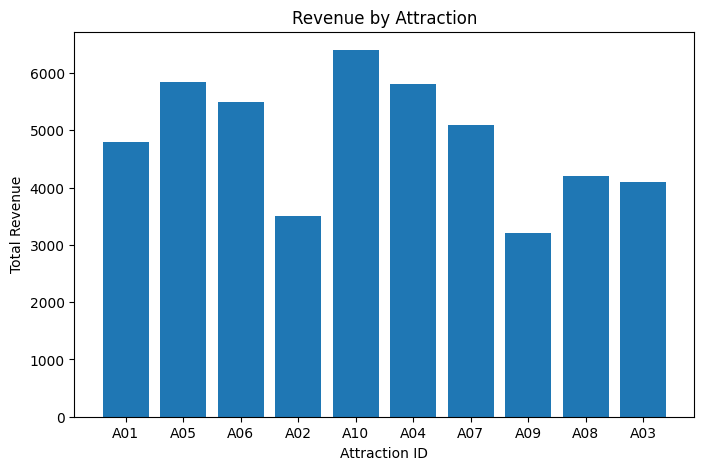

In [0]:
display(gold_df.select("attraction_id", "total_revenue"))
data = gold_df.toPandas()
plt.figure(figsize=(8, 5))
plt.bar(data["attraction_id"], data["total_revenue"])
plt.xlabel("Attraction ID")
plt.ylabel("Total Revenue")
plt.title("Revenue by Attraction")
plt.show()

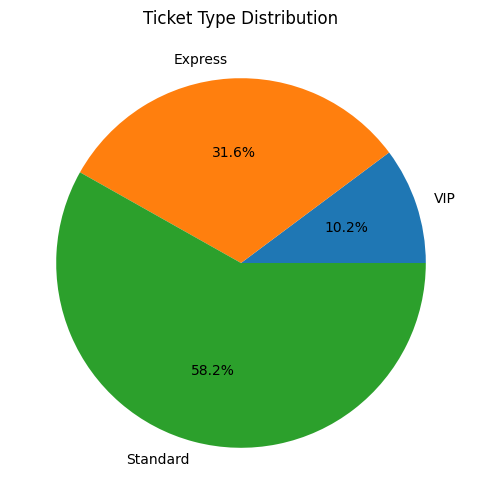

In [0]:
ticket_share_df = silver_df.groupBy("ticket_type").count()
data = ticket_share_df.toPandas()
plt.figure(figsize=(6, 6))
plt.pie(data["count"], labels=data["ticket_type"], autopct="%1.1f%%")
plt.title("Ticket Type Distribution")
plt.show()

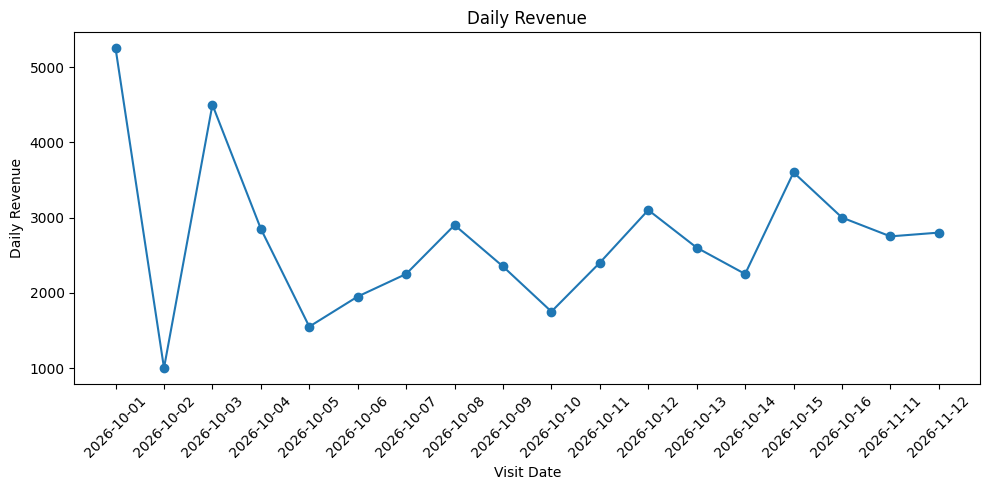

In [0]:
daily_revenue_df = silver_df.groupBy("visit_date").agg(
    sum("revenue").alias("daily_revenue")
).orderBy("visit_date")
data = daily_revenue_df.toPandas()
plt.figure(figsize=(10, 5))
plt.plot(data["visit_date"], data["daily_revenue"], marker="o")
plt.xlabel("Visit Date")
plt.ylabel("Daily Revenue")
plt.title("Daily Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

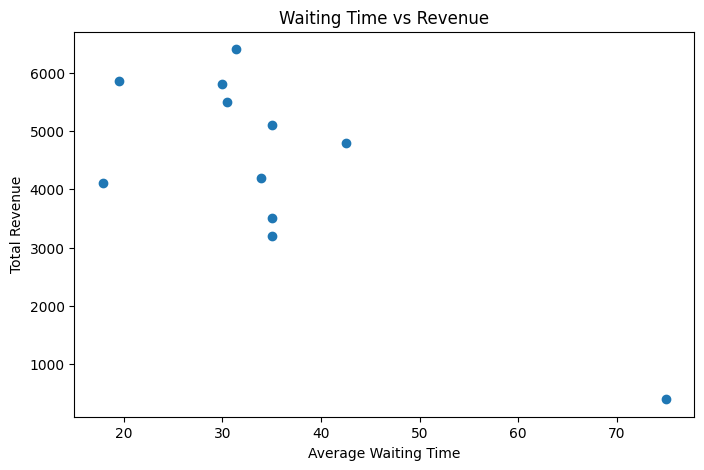

In [0]:
scatter_df = silver_df.groupBy("attraction_id").agg(
    avg("wait_minutes").alias("average_wait"),
    sum("revenue").alias("total_revenue")
)
data = scatter_df.toPandas()
plt.figure(figsize=(8, 5))
plt.scatter(data["average_wait"], data["total_revenue"])
plt.xlabel("Average Waiting Time")
plt.ylabel("Total Revenue")
plt.title("Waiting Time vs Revenue")
plt.show()